# LXT reference vs our zennit rules — ViT-B/16, WEIGHTS SWAPPED

Verbatim copy of `lxt_reference.ipynb` with the checkpoints exchanged:
the torchvision skeleton (paths A/B) carries the timm `augreg2_in21k_ft_in1k`
weights, the timm skeleton (path A2) carries the torchvision `IMAGENET1K_V1`
weights. Each path uses its weights' native preprocessing. Hypothesis: only
the weights determine the saliency maps → the maps swap relative to
`lxt_reference.ipynb`.

## 1. Setup

In [1]:
from __future__ import annotations
from pathlib import Path

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / 'pyproject.toml').is_file():
    REPO_ROOT = REPO_ROOT.parent

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torchvision
from torchvision.models import vit_b_16, ViT_B_16_Weights

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0)
print(f'torch        : {torch.__version__}')
print(f'torchvision  : {torchvision.__version__}')
print(f'device       : {DEVICE}')

torch        : 2.11.0+cu130
torchvision  : 0.26.0+cu130
device       : cuda


## 2. Load torchvision ViT-B/16 + sample image

weights swapped: torchvision skeleton <- augreg2, timm skeleton <- IMAGENET1K_V1
top-1 class  : 40 (American chameleon)
top-1 logit  : 8.6248
top-5 classes: [40, 46, 988, 38, 44] (American chameleon, green lizard, acorn, banded gecko, alligator lizard)
input shape  : (1, 3, 224, 224)


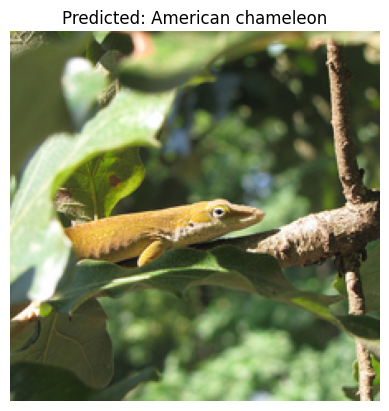

In [2]:
weights = ViT_B_16_Weights.IMAGENET1K_V1
preprocess = weights.transforms()
categories = weights.meta['categories']

model = vit_b_16(weights=weights).to(DEVICE).eval()

# ── swap weights between the two skeletons ─────────────────────────────────
import re
from torchvision.transforms import functional as TF
from experiments.models import MODELS, backbone_transforms

model_a2_wrapped = MODELS["vit_base_imagenet"](device=DEVICE)   # timm M2 skeleton
timm_backbone = model_a2_wrapped.backbone

def timm_key_from_tv(k):
    # torchvision state-dict key -> timm state-dict key (1:1 bijection)
    k = k.replace('class_token', 'cls_token').replace('conv_proj', 'patch_embed.proj')
    k = k.replace('encoder.pos_embedding', 'pos_embed')
    m = re.match(r'encoder\.layers\.encoder_layer_(\d+)\.(.*)', k)
    if m:
        i, rest = m.groups()
        rest = (rest.replace('ln_1', 'norm1').replace('ln_2', 'norm2')
                    .replace('self_attention.in_proj_weight', 'attn.qkv.weight')
                    .replace('self_attention.in_proj_bias', 'attn.qkv.bias')
                    .replace('self_attention.out_proj', 'attn.proj')
                    .replace('mlp.0', 'mlp.fc1').replace('mlp.3', 'mlp.fc2'))
        return f'blocks.{i}.{rest}'
    return k.replace('encoder.ln', 'norm').replace('heads.head', 'head')

# cloned snapshots (state_dict returns references; loading would mutate them)
v1_weights  = {k: v.clone() for k, v in model.state_dict().items()}
aug_weights = {k: v.clone() for k, v in timm_backbone.state_dict().items()}
tv_key_from_timm = {timm_key_from_tv(k): k for k in v1_weights}

timm_backbone.load_state_dict({timm_key_from_tv(k): v for k, v in v1_weights.items()}, strict=True)
model.load_state_dict({tv_key_from_timm[k]: v for k, v in aug_weights.items()}, strict=True)
print('weights swapped: torchvision skeleton <- augreg2, timm skeleton <- IMAGENET1K_V1')

img_path = REPO_ROOT / 'tutorials' / 'images' / 'lizard.jpg'
pil = Image.open(img_path).convert('RGB')

# preprocessing follows the WEIGHTS: this skeleton now carries augreg2,
# so use the timm transform (geometry-only) + timm normalization
transform_aug, normalize_aug = backbone_transforms(timm_backbone)
img01 = transform_aug(pil)
x_norm = normalize_aug(img01.unsqueeze(0).to(DEVICE))

with torch.no_grad():
    logits = model(x_norm)
top1 = int(logits.argmax(-1).item())
print(f'top-1 class  : {top1} ({categories[top1]})')
print(f'top-1 logit  : {logits[0, top1].item():.4f}')
top5 = [int(i) for i in logits.topk(5, dim=-1).indices[0].tolist()]
print(f'top-5 classes: {top5} ({", ".join(categories[i] for i in top5)})')
print(f'input shape  : {tuple(x_norm.shape)}')

img_disp = img01.permute(1, 2, 0).numpy()   # display the un-normalized [0,1] image
TARGET_CLASS = top1   # attribute against the top-1 class
plt.imshow(img_disp)
plt.title(f'Predicted: {categories[top1]}')
plt.axis('off')
plt.show()

## 3. Path A — our composite (grad×input, unified canonization, no LXT)

In [3]:
import torch.nn as nn
from zennit.core import BasicHook, Composite

from zennit_extensions.attention_unfolded import FFNLinear, KInspectionLayer, QInspectionLayer
from zennit_extensions.canonisation.canonizers import (
    FFNLinearSubstitutionCanonizer,
    LayerNormSubstitutionCanonizer,
    VanillaViTAttentionSubstitutionCanonizer,
)
from zennit_extensions.cp_lrp import StopGradient
from zennit_extensions.rules.attnlrp import (
    GammaGradInput,
    IdentityGradTimesInput,
    TorchvisionEncoderBlockCanonizer,
)

# guard: run before the LXT cell (LXT patches zennit BasicHook process-wide)
assert "lxt" not in BasicHook.backward.__module__, "restart kernel, run Path A first"

GAMMA_CONV = GammaGradInput(gamma=0.25)
GAMMA_LIN = GammaGradInput(gamma=0.10)
GELU_RULE = IdentityGradTimesInput(epsilon=1e-10)
STOP = StopGradient()


def unified_map(ctx, name, module):
    # ONE map for both skeletons — canonizers below expose the same layout.
    if isinstance(module, nn.Conv2d):
        return GAMMA_CONV                       # patch embed
    if isinstance(module, FFNLinear):
        return GAMMA_LIN                        # FFN linears (marker type)
    if isinstance(module, nn.Linear) and name.split(".")[-1] == "head":
        return GAMMA_LIN                        # classifier head
    # bare nn.Linear (qkv / proj) -> no hook = epsilon in the g-convention
    if isinstance(module, nn.GELU):
        return GELU_RULE                        # y/(x+eps) gain identity
    if isinstance(module, (QInspectionLayer, KInspectionLayer)):
        return STOP                             # CP-LRP: no relevance into Q/K
    return None


# skeleton-specific canonization -> identical post-canonization layout
CANONIZERS_TORCHVISION = lambda: [
    LayerNormSubstitutionCanonizer(),           # sigma-detach on every LN
    FFNLinearSubstitutionCanonizer(),           # mark MLP linears as FFNLinear
    TorchvisionEncoderBlockCanonizer(),         # unfold fused MHA to timm layout
]
CANONIZERS_TIMM = lambda: [
    LayerNormSubstitutionCanonizer(),
    FFNLinearSubstitutionCanonizer(),
    VanillaViTAttentionSubstitutionCanonizer(block_indices=None),
]

composite_a = Composite(module_map=unified_map, canonizers=CANONIZERS_TORCHVISION())

x_a = x_norm.detach().clone().requires_grad_(True)
with composite_a.context(model):
    out_a = model(x_a)
    out_a[0, TARGET_CLASS].backward()          # seed g=1 at the target logit

R_a = (x_a.grad * x_a).detach().cpu()          # relevance read-out: grad x input
heatmap_a = R_a.sum(dim=1)[0].numpy()
logit_a = out_a[0, TARGET_CLASS].item()
print(f'Path A | sum |R| = {R_a.abs().sum().item():.4e}'
      f'   logit = {logit_a:.4f}'
      f'   R-sum / logit = {R_a.sum().item() / logit_a:.4f}')


Path A | sum |R| = 1.4123e+01   logit = 8.6248   R-sum / logit = 0.8940


## 3b. Path A2 — SAME unified map, timm skeleton

In [4]:
# timm M2 skeleton, carrying the torchvision IMAGENET1K_V1 weights (swap cell)
model_a2 = model_a2_wrapped

# preprocessing follows the WEIGHTS: V1 preset geometry + normalization
img01_a2 = TF.to_tensor(TF.center_crop(TF.resize(pil, preprocess.resize_size), preprocess.crop_size))
x_norm_a2 = TF.normalize(img01_a2, preprocess.mean, preprocess.std).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    logits_a2 = model_a2(x_norm_a2)
TARGET_A2 = int(logits_a2.argmax(-1).item())
print(f'M2 top-1: {TARGET_A2} ({categories[TARGET_A2]})  '
      f'(torchvision path target: {TARGET_CLASS} ({categories[TARGET_CLASS]}))')

# SAME unified map; only the canonizer list is skeleton-specific.
composite_a2 = Composite(module_map=unified_map, canonizers=CANONIZERS_TIMM())

x_a2 = x_norm_a2.detach().clone().requires_grad_(True)
with composite_a2.context(model_a2):
    out_a2 = model_a2(x_a2)
    out_a2[0, TARGET_A2].backward()

R_a2 = (x_a2.grad * x_a2).detach().cpu()
heatmap_a2 = R_a2.sum(dim=1)[0].numpy()
logit_a2 = out_a2[0, TARGET_A2].item()
print(f'Path A2 | sum |R| = {R_a2.abs().sum().item():.4e}'
      f'   logit = {logit_a2:.4f}'
      f'   R-sum / logit = {R_a2.sum().item() / logit_a2:.4f}')


M2 top-1: 40 (American chameleon)  (torchvision path target: 40 (American chameleon))
Path A2 | sum |R| = 7.6042e+00   logit = 8.6909   R-sum / logit = 0.4519


## 4. Path B — LXT baseline (all patching in one cell)

In [5]:
# ═══ ALL LXT PATCHING — this cell and nowhere else ═══════════════════════
APPLY_ZENNIT_PATCH = True   # False → skip the BasicHook patch, see the mismatch

# --- import shim: lxt 2.1's package __init__ pulls HF model wrappers that
# --- pre-date transformers>=5; stub them, we only need vit_torch.
import sys, types
for _name in ('llama', 'qwen2', 'qwen3', 'gemma3', 'bert', 'gpt2'):
    _full = f'lxt.efficient.models.{_name}'
    _stub = types.ModuleType(_full)
    setattr(_stub, f'modeling_{_name}', types.ModuleType(f'modeling_{_name}'))
    _stub.attnLRP = {}
    sys.modules[_full] = _stub

from torchvision.models import vision_transformer
from lxt.efficient import monkey_patch, monkey_patch_zennit
from lxt.efficient.models import vit_torch

# --- 1. what the cp_LRP recipe patches, explicitly ------------------------
print('LXT vit_torch.cp_LRP patch map (class → replacement):')
for cls, repl in vit_torch.cp_LRP.items():
    print(f'  {cls.__module__}.{cls.__name__:22s} → {getattr(repl, "__name__", repl)}')

# --- 2. apply the class-level module rewrites -----------------------------
monkey_patch(vision_transformer, verbose=True)

# --- 3. the zennit BasicHook grad×input patch (optional) ------------------
if APPLY_ZENNIT_PATCH:
    monkey_patch_zennit(verbose=True)
else:
    print('BasicHook patch SKIPPED — Gamma rules will emit relevance into a '
          'grad×input stream; expect the comparison to break down.')


LXT vit_torch.cp_LRP patch map (class → replacement):
  torch.nn.modules.activation.GELU                   → functools.partial(<function patch_method at 0x7fd32d11b6a0>, <function non_linear_forward at 0x7fd32d118e00>, keep_original=True)
  torch.nn.modules.normalization.LayerNorm              → functools.partial(<function patch_method at 0x7fd32d11b6a0>, <function layer_norm_forward at 0x7fd32d118fe0>)
  torch.nn.modules.activation.MultiheadAttention     → functools.partial(<function patch_method at 0x7fd32d11b6a0>, <function cp_multi_head_attention_forward at 0x7fd32d98f380>, keep_original=True)
Patched GELU
Patched LayerNorm
Patched MultiheadAttention
Patched Zennit BasicHook's forward
Patched Zennit BasicHook's backward


In [6]:
from zennit.rules import Gamma
from zennit.composites import LayerMapComposite

# Path B backward — LXT convention: the backward stream carries g with
# R = g·x, so the heatmap is x.grad * x. Same Gamma layer_map as Path A,
# NO canonizers — the class-level patches cover GELU/LayerNorm/MHA.
layer_map_b = [
    (nn.Conv2d, Gamma(gamma=0.25)),
    (nn.Linear, Gamma(gamma=0.10)),
]
composite_b = LayerMapComposite(layer_map=layer_map_b, canonizers=[])

x_b = x_norm.detach().clone().requires_grad_(True)
with composite_b.context(model):
    out_b = model(x_b)
    out_b[0, TARGET_CLASS].backward()

R_b = (x_b.grad * x_b).detach().cpu()
heatmap_b = R_b.sum(dim=1)[0].numpy()
logit_b = out_b[0, TARGET_CLASS].item()
print(f'Path B | sum |R| = {R_b.abs().sum().item():.4e}'
      f'   logit = {logit_b:.4f}'
      f'   R-sum / logit = {R_b.sum().item() / logit_b:.4f}')


Path B | sum |R| = 1.4123e+01   logit = 8.6248   R-sum / logit = 0.8940


## 5. Compare

A vs B: same recipe, two implementations — agreement up to attention-kernel
op order (fused vs unfolded, ~1e-6), no longer bit-exact by construction.


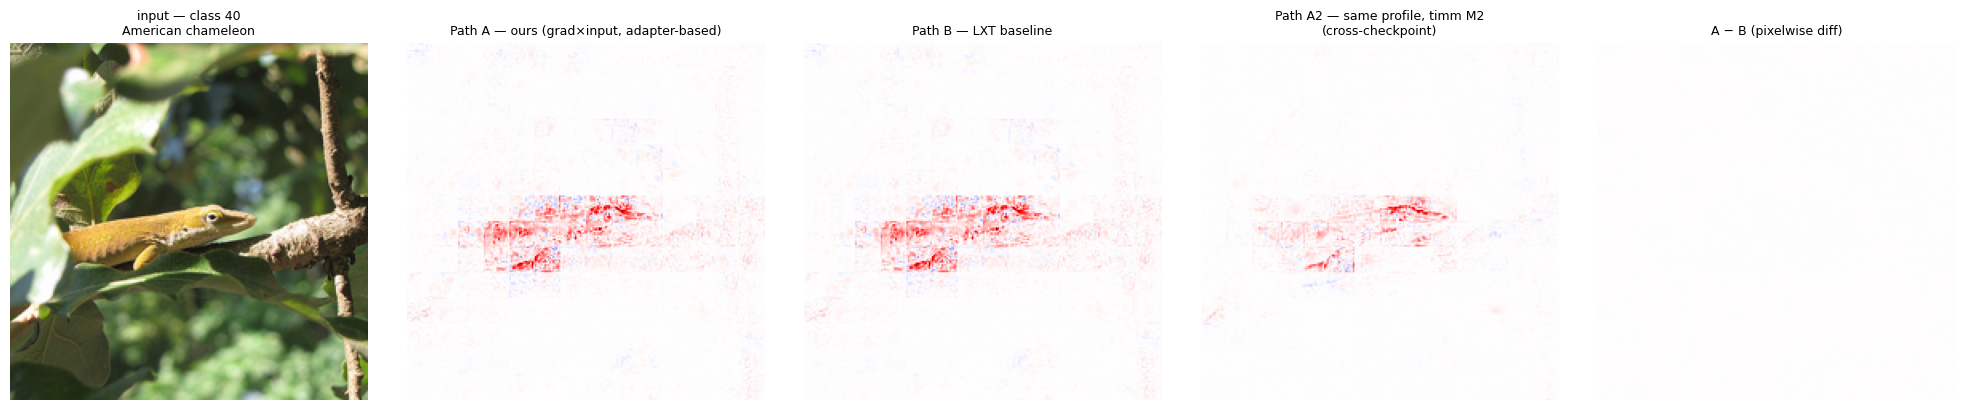

  |R_A| max        : 1.6600e-02
  |R_B| max        : 1.6600e-02
  |R_A - R_B| max  : 5.1772e-08
  |R_A - R_B| mean : 1.2554e-09
  relative ∞-error : 3.1187e-06
  A2 vs B (cross-checkpoint): pearson r = 0.5027   |Δ| max 1.5224e-02   |Δ| mean 2.2019e-04


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_disp); axes[0].axis('off')
axes[0].set_title(f'input — class {TARGET_CLASS}\n{categories[TARGET_CLASS]}', fontsize=9)

vmax = 0.0
for ax, (hm, title) in zip(axes[1:-1], [
        (heatmap_a, 'Path A — ours (grad×input, adapter-based)'),
        (heatmap_b, 'Path B — LXT baseline'),
        (heatmap_a2, 'Path A2 — same profile, timm M2\n(cross-checkpoint)'),]):
    vmax_tmp = float(np.abs(hm).max() or 1.0)
    vmax = max(vmax, vmax_tmp)
    ax.imshow(hm, cmap='seismic', vmin=-vmax, vmax=vmax)
    ax.axis('off'); ax.set_title(title, fontsize=9)

diff_a = heatmap_a - heatmap_b
axes[-1].imshow(diff_a, cmap='seismic', vmin=-vmax, vmax=vmax)
axes[-1].axis('off'); axes[-1].set_title('A − B (pixelwise diff)', fontsize=9)

plt.tight_layout(); plt.show()

print(f'  |R_A| max        : {np.abs(heatmap_a).max():.4e}')
print(f'  |R_B| max        : {np.abs(heatmap_b).max():.4e}')
print(f'  |R_A - R_B| max  : {np.abs(diff_a).max():.4e}')
print(f'  |R_A - R_B| mean : {np.abs(diff_a).mean():.4e}')
if np.abs(heatmap_a).max() > 0:
    print(f'  relative ∞-error : {np.abs(diff_a).max() / np.abs(heatmap_a).max():.4e}')

# A2 vs B: different checkpoints — descriptive stats only
d2 = heatmap_a2 - heatmap_b
r = float(np.corrcoef(heatmap_a2.ravel(), heatmap_b.ravel())[0, 1])
print(f"  A2 vs B (cross-checkpoint): pearson r = {r:.4f}"
      f"   |Δ| max {np.abs(d2).max():.4e}   |Δ| mean {np.abs(d2).mean():.4e}")
